In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


In [ ]:
def gremban_lift(L):
    """
    Constructs the Gremban expansion matrix M from a given matrix L.
    
    Args:
        L (numpy.ndarray): The input matrix (usually a Laplacian).
        
    Returns:
        numpy.ndarray: The 2n x 2n Gremban expansion matrix.
    """
    # Ensure input is a NumPy array
    L = np.array(L)
    
    # Get the size of the matrix (number of rows)
    n = L.shape[0]
    
    # Initialize a 2n x 2n matrix of zeros
    M = np.zeros((2 * n, 2 * n), dtype=float)

    for i in range(n):
        # Set diagonal elements for both diagonal blocks
        # Julia: M[i,i] and M[i+n,i+n]
        
        #M[i, i] = L[i, i]
        #M[i + n, i + n] = L[i, i]

        # Loop through the upper triangle (excluding diagonal)
        # Julia: for j in i+1:n
        Off_set_diag= 0
        for j in range(i + 1, n):
            val = L[i, j]
            
            if val > 0:
                # "Bad" edges (positive off-diagonals) move to the off-diagonal blocks (A)
                # We negate the value as per the standard Gremban reduction
                M[i, n + j] = -val
                M[j, n + i] = -val
                M[n + i, j] = -val
                M[n + j, i] = -val
                Off_set_diag += val
                print(f" sum is{Off_set_diag}, val is {val}")
            else:
                # "Good" edges (negative off-diagonals) stay in the diagonal blocks
                M[i, j] = val
                M[j, i] = val
                M[i + n, j + n] = val
                M[j + n, i + n] = val
                Off_set_diag += -val
                print(f" sum is{Off_set_diag}, val is {-val}")
        print(f" round {i}, off is {Off_set_diag}")
        diff = L[i,i]-Off_set_diag
        M[i,i] = Off_set_diag+ diff/2
        M[i + n, i + n] = M[i, i]    
        M[i,i+n] =    diff/2
        M[i+n,i] = diff/2
    return M
    

In [26]:
test_SDD = [
    [ 1, 1,  0,  0],
    [1,  2, -1,  0],
    [ 0, -1,  2, -1],
    [ 0,  0, -1,  1]
]
gremban_lift(test_SDD)

 sum is1, val is 1
 sum is1, val is 0
 sum is1, val is 0
1
 sum is1, val is 1
 sum is1, val is 0
1
 sum is1, val is 1
1
0


array([[ 1. ,  0. ,  0. ,  0. ,  0. , -1. ,  0. ,  0. ],
       [ 0. ,  1.5, -1. ,  0. , -1. ,  0.5,  0. ,  0. ],
       [ 0. , -1. ,  1.5, -1. ,  0. ,  0. ,  0.5,  0. ],
       [ 0. ,  0. , -1. ,  0.5,  0. ,  0. ,  0. ,  0.5],
       [ 0. , -1. ,  0. ,  0. ,  1. ,  0. ,  0. ,  0. ],
       [-1. ,  0.5,  0. ,  0. ,  0. ,  1.5, -1. ,  0. ],
       [ 0. ,  0. ,  0.5,  0. ,  0. , -1. ,  1.5, -1. ],
       [ 0. ,  0. ,  0. ,  0.5,  0. ,  0. , -1. ,  0.5]])

In [3]:

def draw_graph_from_laplacian(laplacian_matrix):
    """
    Parses a Laplacian matrix and draws the corresponding graph.
    """
    # 1. Convert input to a Numpy array
    L = np.array(laplacian_matrix)
    
    # Check if the matrix is square
    if L.shape[0] != L.shape[1]:
        raise ValueError("Matrix must be square.")

    # 2. Reconstruct the Adjacency Matrix (A)
    # Since L = D - A, then A = -L (for off-diagonal elements)
    adj_matrix = -L
    
    # Set the diagonal to 0 (assuming a simple graph with no self-loops)
    np.fill_diagonal(adj_matrix, 0)
    
    # Replace negative values with 0 (just a safeguard against bad input)
    adj_matrix[adj_matrix < 0] = 0

    # 3. Create the graph using NetworkX
    # This automatically handles weights if the Laplacian values are not just -1
    G = nx.from_numpy_array(adj_matrix)

    # 4. Draw the graph
    plt.figure(figsize=(6, 6))
    
    # Use a spring layout to space nodes out naturally
    pos = nx.spring_layout(G) 
    
    # Draw nodes, edges, and labels
    nx.draw(G, pos, 
            with_labels=True, 
            node_color='lightblue', 
            edge_color='gray', 
            node_size=700, 
            font_size=12,
            width=2) # Line width of edges
            
    # Draw edge labels (weights) if the graph is weighted
    edge_labels = nx.get_edge_attributes(G, "weight")
    # Only draw weights if they are not all 1 (unweighted standard graph)
    if any(w != 1 for w in edge_labels.values()):
        nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

    plt.title("Graph Visualization from Laplacian")
    plt.axis("off")
    plt.show()



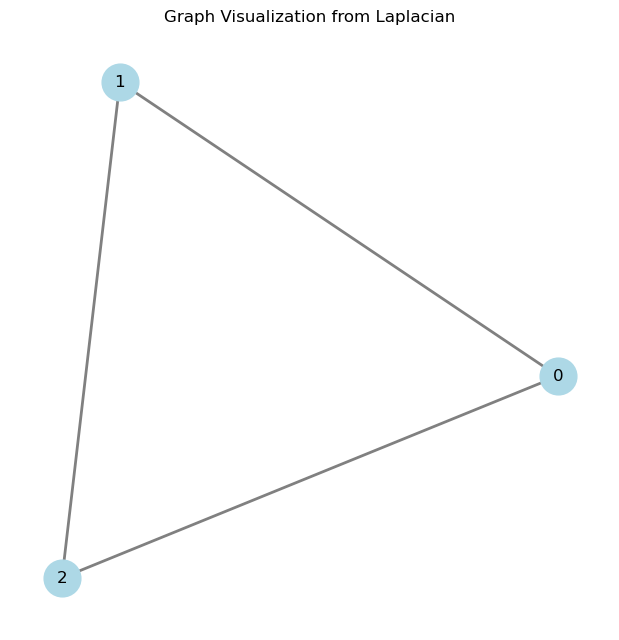

In [4]:
# --- Example Usage ---

# Example: A simple Triangle Graph (K3)
# Degrees are 2, edges are -1
triangle_laplacian = [
    [ 2, -1, -1],
    [-1,  2, -1],
    [-1, -1,  2]
]


# Run the function with the path example
draw_graph_from_laplacian(triangle_laplacian)

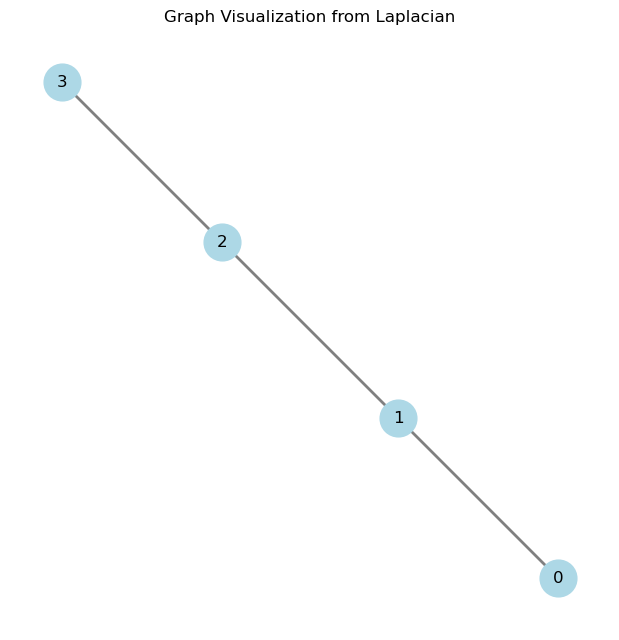

In [5]:
# Example: A path graph 0-1-2-3
path_laplacian = [
    [ 1, -1,  0,  0],
    [-1,  2, -1,  0],
    [ 0, -1,  2, -1],
    [ 0,  0, -1,  1]
]

# Run the function with the path example
draw_graph_from_laplacian(path_laplacian)